# Missing taxa: the benchmark

The published benchmarks' gene trees with ingroup taxa deleted, tree by tree (`taxmiss_eval/`). A **condition**
`p<P>_c<CAP>` deletes from a tree with probability `p`, at most `CAP`% of `n` taxa (the MANIFEST's `M`); `missing.tsv`
records what each tree lost. The same networks, the same 1,000 loci and the same trees, pruned — so every cell is
**paired** with its published (**control**) cell, which is the ztc benchmark itself (`nni_ensemble/results/<ds>_bench.csv`).

Four methods, as in `plotting_ztc_bench.ipynb`:
- **GNN**: the vanilla emitted network, drawn beside RIDDLE as its reference --
  `ours/l2mix_pair/selF1`, relaxed L2 (L3 on L3reg), run with `run_gnn_cpu.py --partial 4` — each partial tree's
  own leaf set is dropped from the clusters it contributes. Well out of the training distribution, which saw only
  full-taxon trees.
- **RIDDLE** (`GNN MAP [z+tc]` in the tables): `nni_ensemble`'s MAP over the GNN's low-z blocks, scored by
  **one `beta` fitted on the GNN's own training networks** and selected on its validation networks, in the control
  and under every condition
  (`MAP_FIT = "train"`; `nni_ensemble/README.md`, "Train-fit calibration"; `"cross"` restores the published
  fit, the parent network's held-out fold, no refit). The triple concordance `tc` uses the partial-aware kernel
  (an absent taxon is never an outgroup). Only the train-fit MAP is RIDDLE: under `"cross"` the figures say
  `GNN MAP [z+tc] (cross-fit)`.
- **BROOQS**, **NetCS**: on TREE-QMC's tree of blobs of the partial trees (raw TOB, rooted on OUT). On the NetCS
  dataset the published control ran both **unrooted**, with no OUT anywhere (`netcs_eval/run_resolvers.py`), while
  the conditions run them rooted on the oracle OUT (`BROOQS*` / `NetCS*`, as the 500-tree subsample did): their
  condition − control delta is **cross-protocol**, drawn hollow in §2. Every comparison within one condition, and
  every GNN and RIDDLE delta, is protocol-matched.

**NetCS's conditions also re-root some trees.** Their ingroup is exactly the parent's tree pruned, but the Linux box
placed OUT anew on the pruned trees: on 4.7% of them (2–10% by phase and ILS, highest at n = 50 and low ILS; mostly
among the true-root oracle's tied edges) OUT sits on another edge than pruning the parent gives
(`taxmiss_eval/README.md`, NetCS; per cell in `taxmiss_eval/staged/netcs/<cond>/t1b.tsv`). Every method's NetCS
condition − control delta includes that re-rooting; CAMUS, L2reg and L3reg are pure prunings.

**Inputs.** Every table is built by a script with gates; the notebook only reads and draws.

| table | built by | what it holds |
|---|---|---|
| `nni_ensemble/results/trainfit/derived/<ds>_tm_<cond>_bench.csv` (`"cross"`: `results/derived/`) | `run_trainfit.sh derived` (`"cross"`: `run_derived.sh rest tm-*`) | accuracy, one row per (headline cell, method), condition `cond` |
| `nni_ensemble/results/trainfit/<ds>_bench.csv` (`"cross"`: `results/`) | the ztc bench, under the same fit | the control |
| `taxmiss_eval/results/<ds>_taxmiss.csv` | `taxmiss_eval/make_csv.py` | per network: missingness, TOB error (and the control TOB's), runtimes |
| `nni_ensemble/results/<ds>_runtime.csv` | the published ztc runtime table | control runtimes |
| `taxmiss_eval/inputs/<ds>/MANIFEST.tsv` | the Linux box | the conditions |

Conditions are found by what is staged (`taxmiss_eval/staged/<ds>/<cond>/CELLS.tsv`), so this notebook grows as they land;
figure 7 waits for a second condition. CAMUS keeps its headline arm (`cam_g500`, n = 50..200), as every other notebook.

Environment: `phylo-env`. Figures go to `../plots/{TITLE}-taxmiss-<figure>-ours_l2mix_pair_selF1.png`.

In [1]:
import json
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import wilcoxon

ROOT = Path("..")
# Which beta scores the GNN MAP [z+tc] (nni_ensemble/README.md, "Train-fit calibration"):
#   "train" -- fitted on the GNN's own training networks, selected on its validation networks, and transferred
#              unchanged (no dataset offsets) to every dataset: nni_ensemble/results/trainfit/
#   "cross" -- the published fit, cross-fitted on the benchmarks themselves: nni_ensemble/results/
# Control and condition MAP rows always come from the same fit; runtimes are the published tables.
MAP_FIT = "train"
RUNTIME_DIR = ROOT / "notebooks" / "data" / "results"
BENCH_DIR = RUNTIME_DIR / {"train": "trainfit", "cross": ""}[MAP_FIT]
print(f"GNN MAP [z+tc] beta: MAP_FIT = {MAP_FIT!r} | bench tables from {BENCH_DIR}")
# RIDDLE is the MAP under the train-fit beta, and only that: under "cross" the figures name the cross-fit instead
MAP_NAME = {"train": "RIDDLE", "cross": "MAP (cross-fit)"}[MAP_FIT]
DERIVED = BENCH_DIR / "derived"
TM = ROOT / "taxmiss_eval"
FIG_DIR = ROOT / "plots"

TAG = "ours_l2mix_pair_selF1"
FAMS = ["camus", "l2reg", "l3reg", "netcs"]
TITLES = {"camus": "CAMUS-data", "l2reg": "L2reg", "l3reg": "L3reg", "netcs": "NetCS-data"}
LEVEL = {"camus": 2, "l2reg": 2, "l3reg": 3, "netcs": 2}
MAP_M = "GNN MAP [z+tc]"
METHODS = ["GNN", MAP_M, "BROOQS", "NetCS"]
LABELS = {"GNN": "GNN", MAP_M: {"train": "RIDDLE", "cross": "GNN MAP\n[z+tc]\n(cross-fit)"}[MAP_FIT],
          "BROOQS": "BROOQS", "NetCS": "NetCS"}
# The published NetCS control ran BROOQS and NetCS unrooted with no OUT; the NetCS conditions run them rooted on the
# oracle OUT (BROOQS* / NetCS*), so their condition - control delta mixes protocol with missingness (hollow in §2)
CROSS_PROTOCOL = {("netcs", "BROOQS"), ("netcs", "NetCS")}
# plotting_ztc_bench.ipynb's palette and order (the dataviz reference's categorical slots; validate_palette.js PASS)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
COLOR = dict(zip(METHODS, CAT))
MARKER = {"GNN": "o", MAP_M: "s", "BROOQS": "^", "NetCS": "D"}
REF_C, INK, ZERO_C = "#898781", "#52514e", "#898781"
METRICS = [("cluster_f1", "Cluster F1", "higher"),
           ("luay_norm_exact", "Norm. top. distance", "lower"),
           ("ha_balanced_error", "Balanced HAE", "lower")]
CONTROL = "control"
RNG = np.random.default_rng(20261021)
sns.set_style("whitegrid", {"grid.color": "#e6e5e0"})
MISSING = []


def load(path, why, **kw):
    """The table at ``path``, or None -- recorded in MISSING with what it would have shown."""
    path = Path(path)
    if not path.exists():
        MISSING.append(f"{path}: {why}")
        return None
    return pd.read_csv(path, **kw)


def save(fig, ds, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{TITLES.get(ds, ds)}-taxmiss-{name}-{TAG}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("wrote", path)


def boot_mean(x, b=500):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if not len(x):
        return np.nan, np.nan, np.nan
    bs = RNG.choice(x, size=(b, len(x)), replace=True).mean(axis=1)
    return x.mean(), *np.percentile(bs, [2.5, 97.5])


def tint(hex_color, f):
    """``hex_color`` mixed toward white: f = 1 is the colour itself, 0 is white."""
    rgb = np.array([int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]) / 255
    return tuple(1 - f * (1 - rgb))


def conds_of(fam):
    """Staged conditions, in MANIFEST order."""
    man = TM / "inputs" / fam / "MANIFEST.tsv"
    if not man.exists():
        return []
    order = list(dict.fromkeys(pd.read_csv(man, sep="\t", usecols=["cond"]).cond))
    return [c for c in order if c != CONTROL and (TM / "staged" / fam / c / "CELLS.tsv").exists()]


def cond_pc(c):
    m = re.fullmatch(r"p([0-9.]+)_c(\d+)", c)
    return (float(m.group(1)), int(m.group(2))) if m else (np.nan, np.nan)


def cond_label(c):
    if c == CONTROL:
        return "control"
    p, cap = cond_pc(c)
    return f"p {p:.2f}, cap {cap}%"


def shade(conds):
    """Fill strength per condition: control pale and hatched, conditions full (graded when several)."""
    out = {CONTROL: 0.35}
    rest = [c for c in conds if c != CONTROL]
    for i, c in enumerate(rest):
        out[c] = 1.0 if len(rest) == 1 else 0.55 + 0.45 * i / (len(rest) - 1)
    return out


def grouped_boxes(ax, data, methods, conds, *, n_ref=None):
    """Per method a group of boxes, one per condition (control first): median, quartiles, 1.5-IQR whiskers,
    a white diamond at the mean, cells as points when there are at most 60.  Empty slots say "not run"."""
    sh = shade(conds)
    w = 0.8 / len(conds)
    for i, m in enumerate(methods):
        for j, c in enumerate(conds):
            v = np.asarray(data.get((m, c), []), float)
            v = v[~np.isnan(v)]
            x = i + 1 - 0.4 + w * (j + 0.5)
            if not len(v):
                tr = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
                ax.text(x, 0.5, "not run", transform=tr, rotation=90, ha="center", va="center", color=REF_C, fontsize=6)
                continue
            few = len(v) <= 60
            bp = ax.boxplot([v], positions=[x], widths=w * 0.85, patch_artist=True, showfliers=not few,
                            medianprops=dict(color="#222", lw=1.2), whiskerprops=dict(color="#555"),
                            capprops=dict(color="#555"),
                            flierprops=dict(marker=".", ms=2, mfc=REF_C, mec="none", alpha=0.6))
            patch = bp["boxes"][0]
            patch.set_facecolor(tint(COLOR[m], sh[c]))
            patch.set_edgecolor("#333")
            if c == CONTROL:
                patch.set_hatch("///")
            if few:
                ax.scatter(x + RNG.uniform(-w * 0.25, w * 0.25, len(v)), v, s=4, color=INK, alpha=0.45, lw=0, zorder=3)
            ax.scatter([x], [v.mean()], marker="D", s=14, color="white", edgecolor="#222", zorder=4)
    ax.set_xticks(np.arange(1, len(methods) + 1))
    ax.set_xticklabels([LABELS[m] for m in methods], fontsize=8)
    ax.set_xlim(0.4, len(methods) + 0.6)


def cond_legend(fig, conds, **kw):
    sh = shade(conds)
    handles = [Patch(facecolor=tint("#52514e", sh[c]), edgecolor="#333", hatch="///" if c == CONTROL else None,
                     label=cond_label(c)) for c in conds]
    fig.legend(handles=handles, frameon=False, fontsize=8, **kw)


def wilcoxon_p(d):
    d = np.asarray(d, float)
    d = d[~np.isnan(d)]
    if len(d) < 2 or not np.any(d):
        return np.nan
    return wilcoxon(d, zero_method="pratt").pvalue

GNN MAP [z+tc] beta: MAP_FIT = 'train' | bench tables from ../nni_ensemble/results/trainfit


In [2]:
ACC, PN, MAN, RTC, GATES = [], [], [], [], {}
CONDS = {}
for fam in FAMS:
    conds = conds_of(fam)
    if not conds:
        continue
    CONDS[fam] = conds
    ctrl = load(BENCH_DIR / f"{fam}_bench.csv", f"{TITLES[fam]} control (the published ztc bench)")
    if ctrl is not None:
        ACC.append(ctrl.assign(family=fam, cond=CONTROL))
    for cond in conds:
        b = load(DERIVED / f"{fam}_tm_{cond}_bench.csv", f"{TITLES[fam]} {cond} accuracy (run_derived.sh rest)")
        if b is not None:
            ACC.append(b.assign(family=fam, cond=cond))
    p = load(TM / "results" / f"{fam}_taxmiss.csv", f"{TITLES[fam]} per-network rows (taxmiss_eval/make_csv.py)")
    if p is not None:
        g = json.loads((TM / "results" / f"{fam}_taxmiss_gates.json").read_text())
        GATES[f"{fam} per-network"] = f"{g['rows']} rows, {len(g['gaps'])} gaps, {len(g['problems'])} problems"
        assert not g["problems"], g["problems"][:5]
        PN.append(p.assign(family=fam))
    m = pd.read_csv(TM / "inputs" / fam / "MANIFEST.tsv", sep="\t")
    MAN.append(m[m.cond.isin(conds)].assign(family=fam))
    r = load(RUNTIME_DIR / f"{fam}_runtime.csv", f"{TITLES[fam]} control runtimes")
    if r is not None:
        RTC.append(r.assign(family=fam))
for stem in ("taxmiss_camus", "taxmiss_reg", "taxmiss_netcs"):
    f = DERIVED / f"bench_{stem}_gates.json"
    if f.exists():
        g = json.loads(f.read_text())
        assert g["variant"] == "z+tc", g["variant"]
        GATES[stem] = f"{len(g['problems'])} problems | " + ", ".join(
            f"{ds}: {s['cells']} cells, B1 {s.get('b1_cluster_f1', 0)}/{s.get('b1_luay_norm_exact', 0)}/{s.get('b1_ha_balanced_error', 0)}"
            for ds, s in g["stats"].items())
        assert not g["problems"], g["problems"][:5]

ACC = pd.concat(ACC, ignore_index=True) if ACC else pd.DataFrame(columns=["family", "cond", "cell", "method"])
PN = pd.concat(PN, ignore_index=True) if PN else pd.DataFrame()
MAN = pd.concat(MAN, ignore_index=True) if MAN else pd.DataFrame()
RTC = pd.concat(RTC, ignore_index=True) if RTC else pd.DataFrame()
# the control rows that pair with a condition's cells (CAMUS: its headline arm, in both)
FAM_LIST = [f for f in FAMS if f in CONDS and f in set(ACC.family)]
ALL_CONDS = list(dict.fromkeys(c for f in FAM_LIST for c in CONDS[f]))
print("conditions staged:", {f: CONDS[f] for f in CONDS})
for k, v in GATES.items():
    print(f"gates {k}: {v}")


def paired(fam, metric, cond, method):
    """``(cond - control)`` per cell for one method -- set_index/unstack, so a duplicate raises."""
    d = ACC[(ACC.family == fam) & (ACC.method == method) & ACC.cond.isin([CONTROL, cond])]
    w = d.set_index(["cell", "cond"])[metric].unstack("cond")
    if CONTROL not in w or cond not in w:
        return pd.Series(dtype=float)
    return (w[cond] - w[CONTROL]).dropna()

conditions staged: {'camus': ['p0.90_c24'], 'l2reg': ['p0.90_c24'], 'l3reg': ['p0.90_c24'], 'netcs': ['p0.90_c24']}
gates camus per-network: 300 rows, 0 gaps, 0 problems
gates l2reg per-network: 60 rows, 0 gaps, 0 problems
gates l3reg per-network: 60 rows, 0 gaps, 0 problems
gates netcs per-network: 3600 rows, 0 gaps, 0 problems
gates taxmiss_camus: 0 problems | camus_tm_p0.90_c24: 80 cells, B1 80/80/80
gates taxmiss_reg: 0 problems | l2reg_tm_p0.90_c24: 20 cells, B1 20/20/20, l3reg_tm_p0.90_c24: 20 cells, B1 20/20/20
gates taxmiss_netcs: 0 problems | netcs_tm_p0.90_c24: 1200 cells, B1 1200/1200/1200


## 0. Coverage

Cells per (dataset, condition, method), and every status other than `ok`. A condition's cells are the control's,
so a cell missing from the control (the published tables lack L2reg rep07 and 17 NetCS cells, `plotting_ztc_bench`
§0) is unpaired and drops out of the deltas below.

In [3]:
rows = []
for fam in FAM_LIST:
    for cond in [CONTROL, *CONDS[fam]]:
        d = ACC[(ACC.family == fam) & (ACC.cond == cond)]
        row = {"dataset": TITLES[fam], "condition": cond_label(cond), "cells": d.cell.nunique()}
        for m in METHODS:
            s = d[d.method == m]
            row[m] = f"{s.cell.nunique()} ({(s.status.fillna('ok') == 'ok').sum()} ok)" if len(s) else "-"
        rows.append(row)
display(pd.DataFrame(rows).set_index(["dataset", "condition"]))
if len(ACC):
    bad = ACC[ACC.status.fillna("ok") != "ok"]
    display(bad.groupby(["family", "cond", "method", "status"]).size().rename("cells").to_frame())
if len(MAN):
    display(MAN.groupby(["family", "cond"]).agg(cells=("cell", "size"),
                                                 M=("M", lambda s: ",".join(str(int(x)) for x in sorted(set(s)))),
                                                 mean_missing=("mean_missing", "mean"),
                                                 trees_modified=("n_modified", "mean")).round(4))

cells             GNN  GNN MAP [z+tc]  \
dataset    condition                                                
CAMUS-data control             80      80 (80 ok)      80 (80 ok)   
           p 0.90, cap 24%     80      80 (80 ok)      80 (80 ok)   
L2reg      control             19      19 (19 ok)      19 (19 ok)   
           p 0.90, cap 24%     20      20 (20 ok)      20 (20 ok)   
L3reg      control             20      20 (20 ok)      20 (20 ok)   
           p 0.90, cap 24%     20      20 (20 ok)      20 (20 ok)   
NetCS-data control           1183  1183 (1183 ok)  1183 (1183 ok)   
           p 0.90, cap 24%   1200  1200 (1200 ok)  1200 (1200 ok)   

                                    BROOQS           NetCS  
dataset    condition                                        
CAMUS-data control              80 (80 ok)      80 (80 ok)  
           p 0.90, cap 24%      80 (80 ok)      80 (66 ok)  
L2reg      control              19 (19 ok)      19 (18 ok)  
           p 0.90, cap 24%      20 (20 ok)      20 (20 ok)  
L3reg      control              20 (20 ok)      20 (14 ok)  
           p 0.90, cap 24%      20 (20 ok)      20 (11 ok)  
NetCS-data control          1183 (1181 ok)  1183 (1171 ok)  
           p 0.90, cap 24%  1200 (1200 ok)   1200 (838 ok)

cells
family cond      method status                                                   
camus  p0.90_c24 NetCS  out_not_rootable                                       14
l2reg  control   NetCS  out_not_rootable                                        1
l3reg  control   NetCS  error: score: ValueError: duplicate leaf labels         1
                        out_not_rootable                                        5
       p0.90_c24 NetCS  error: rc=-11                                           1
                        out_not_rootable                                        8
netcs  control   BROOQS error: rc=1                                             2
                 NetCS  error: rc=-11                                           9
                        error: score: KeyError: 'A-26832'                       1
                        error: score: KeyError: 'A-9104'                        1
                        error: score: ValueError: duplicate leaf labels         1
       p0.90_c24 NetCS  error: rc=-11                                          47
                        error: score: ValueError: duplicate leaf labels         1
                        error: score: ValueError: taxon set: missing []...      1
                        error: score: ValueError: taxon set: missing []...      1
                        error: score: ValueError: taxon set: missing []...      1
                        error: score: ValueError: taxon set: missing []...      1
                        error: score: ValueError: taxon set: missing []...      1
                        out_not_rootable                                      309

,,cells,M,mean_missing,trees_modified
family,cond,,,,
camus,p0.90_c24,100,"6,12,24,36,48",0.1548,900.2700
l2reg,p0.90_c24,20,48,0.1150,899.0500
l3reg,p0.90_c24,20,48,0.1153,898.5000
netcs,p0.90_c24,1200,"12,24,48,49",0.1481,877.7742


## 1. Accuracy, baseline against missing taxa

Drawn as `plotting_sec3-1.ipynb`'s Main Figure 1: the same sizes, frame and y axis ([0, 1] on every panel), with the
two arms side by side per method as in its Figure 3. Colour is the method, in sec3-1's colours. The vanilla GNN is
not drawn here; §2-§9 keep it.
- The **full** box (left) is the **Baseline**: the published benchmark.
- The **pale, hatched** box (right) is **Missing taxa**: `p0.90_c24` (p 0.90, cap 24%).
- Boxes show the median and quartiles, with whiskers at 1.5 IQR; the **white diamond** is the mean.
- **Grey points** are cells; above 100 cells only the fliers are drawn.

wrote ../plots/AllDatasets-taxmiss-accuracy-ours_l2mix_pair_selF1.png


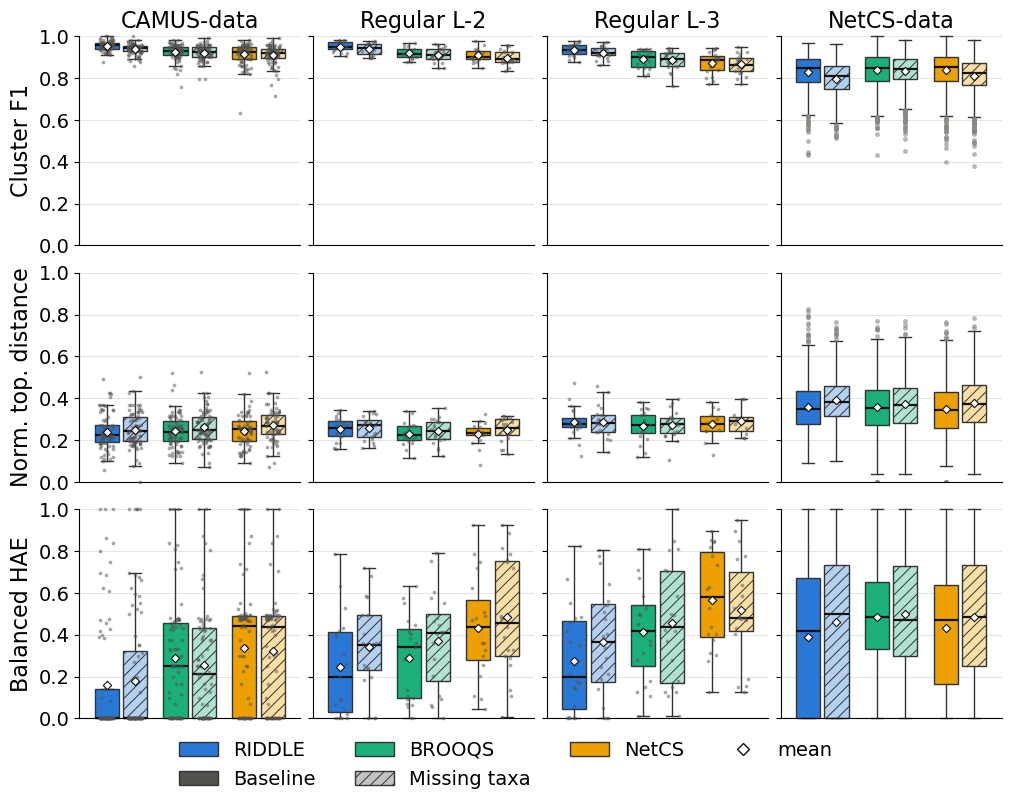

In [4]:
FIGSIZE = (10, 8)
TITLE_FS, LABEL_FS, TICK_FS, LEGEND_FS = 16, 16, 14, 14
YLIM = (0, 1)
GROUP_W = 0.82          # the width one method's boxes share
POINTS_MAX = 100        # every cell is drawn as a point up to this many; fliers only above it
# the arms, left to right within a method: (legend label, fill strength, hatch)
ARMS = {CONTROL: ("Baseline", 1.0, None), "p0.90_c24": ("Missing taxa", 0.35, "///")}
# plotting_sec3-1's methods and colours; the vanilla GNN is left out of this figure
FIG1_METHODS = [MAP_M, "BROOQS", "NetCS"]
FIG1_COLOR = {MAP_M: "#2a78d6", "BROOQS": "#1baf7a", "NetCS": "#eda100"}
FIG1_TITLE = {"camus": "CAMUS-data", "l2reg": "Regular L-2", "l3reg": "Regular L-3", "netcs": "NetCS-data"}
EDGE, MUTED, GRID = "#333333", "#898781", "#e6e5e0"
# plotting_sec3-1's frame: matplotlib's defaults and these, for this figure only (the rest keep seaborn's grid)
SEC31_RC = {"axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
            "hatch.linewidth": 0.7, "savefig.dpi": 300}
# this figure's own jitter generator, so it draws nothing from RNG
rng1 = np.random.default_rng(20261028)

if FAM_LIST:
    step = GROUP_W / len(ARMS)
    with plt.style.context("default"), plt.rc_context(SEC31_RC):
        fig, axes = plt.subplots(len(METRICS), len(FAM_LIST), figsize=FIGSIZE, sharey=True, squeeze=False,
                                 layout="constrained")
        for j, fam in enumerate(FAM_LIST):
            d = ACC[ACC.family == fam]
            for i, (col, name, better) in enumerate(METRICS):
                ax = axes[i, j]
                for s, m in enumerate(FIG1_METHODS):
                    for t, (c, (_, fill, hatch)) in enumerate(ARMS.items()):
                        pos = s + 1 + (t - (len(ARMS) - 1) / 2) * step
                        v = d.loc[(d.method == m) & (d.cond == c), col].dropna().to_numpy()
                        if len(v) == 0:
                            continue
                        few = len(v) <= POINTS_MAX
                        bp = ax.boxplot([v], positions=[pos], widths=0.85 * step, patch_artist=True,
                                        showfliers=not few, medianprops=dict(color="#111111", lw=1.6),
                                        whiskerprops=dict(color=EDGE, lw=1), capprops=dict(color=EDGE, lw=1),
                                        flierprops=dict(marker=".", ms=7, mfc=MUTED, mec="none", alpha=0.6))
                        bp["boxes"][0].set(facecolor=tint(FIG1_COLOR[m], fill), edgecolor=EDGE, linewidth=1,
                                           hatch=hatch)
                        # a value of exactly 0 or 1 sits on the frame, not under it.  Never the fliers: an empty,
                        # unclipped flier line has its bounding box at the figure's origin and wrecks the layout.
                        for artist in bp["boxes"] + bp["whiskers"] + bp["caps"] + bp["medians"]:
                            artist.set_clip_on(False)
                        if few:
                            ax.scatter(pos + rng1.uniform(-0.25, 0.25, len(v)) * step, v, s=7, color=INK,
                                       alpha=0.5, lw=0, zorder=3, clip_on=False)
                        ax.scatter([pos], [v.mean()], marker="D", s=18, color="white", edgecolor="#111111",
                                   lw=0.8, zorder=4, clip_on=False)
                ax.set_xlim(0.4, len(FIG1_METHODS) + 0.6)
                ax.set_xticks([])
                ax.set_ylim(*YLIM)
                ax.tick_params(axis="y", labelsize=TICK_FS)
                ax.grid(axis="y", color=GRID, lw=0.8)
                if i == 0:
                    ax.set_title(FIG1_TITLE[fam], fontsize=TITLE_FS)
                if j == 0:
                    ax.set_ylabel(name, fontsize=LABEL_FS)

        row1 = [Patch(facecolor=FIG1_COLOR[m], edgecolor=EDGE, label=LABELS[m]) for m in FIG1_METHODS]
        row1.append(Line2D([], [], marker="D", ls="", color="white", markeredgecolor="#111111", markersize=6,
                           label="mean"))
        row2 = [Patch(facecolor=tint(INK, fill), edgecolor=EDGE, hatch=hatch, label=label)
                for label, fill, hatch in ARMS.values()]
        row2 += [Patch(facecolor="none", edgecolor="none", label="") for _ in range(len(row1) - len(row2))]
        # a legend fills column by column, so interleaving the two rows lays them out as two rows
        fig.legend(handles=[h for pair in zip(row1, row2) for h in pair], loc="outside lower center",
                   ncol=len(row1), fontsize=LEGEND_FS, frameon=False)
        save(fig, "AllDatasets", "accuracy")
        plt.show()

## 2. What missing taxa cost each method

Per cell, condition − control (paired on the network); mean and 95% bootstrap interval. For cluster F1 below 0 is
worse, for the two errors above 0 is worse. The table counts cells worse / better / tied and gives a Wilcoxon
signed-rank p (Pratt).

**Hollow markers are cross-protocol**: NetCS's resolvers ran unrooted in the control and rooted on the oracle
OUT under the conditions, so that delta is not missing taxa alone (`protocol` in the table). Every NetCS delta also
carries the re-rooting of ~5% of its trees (intro).

wrote ../plots/AllDatasets-taxmiss-delta-ours_l2mix_pair_selF1.png


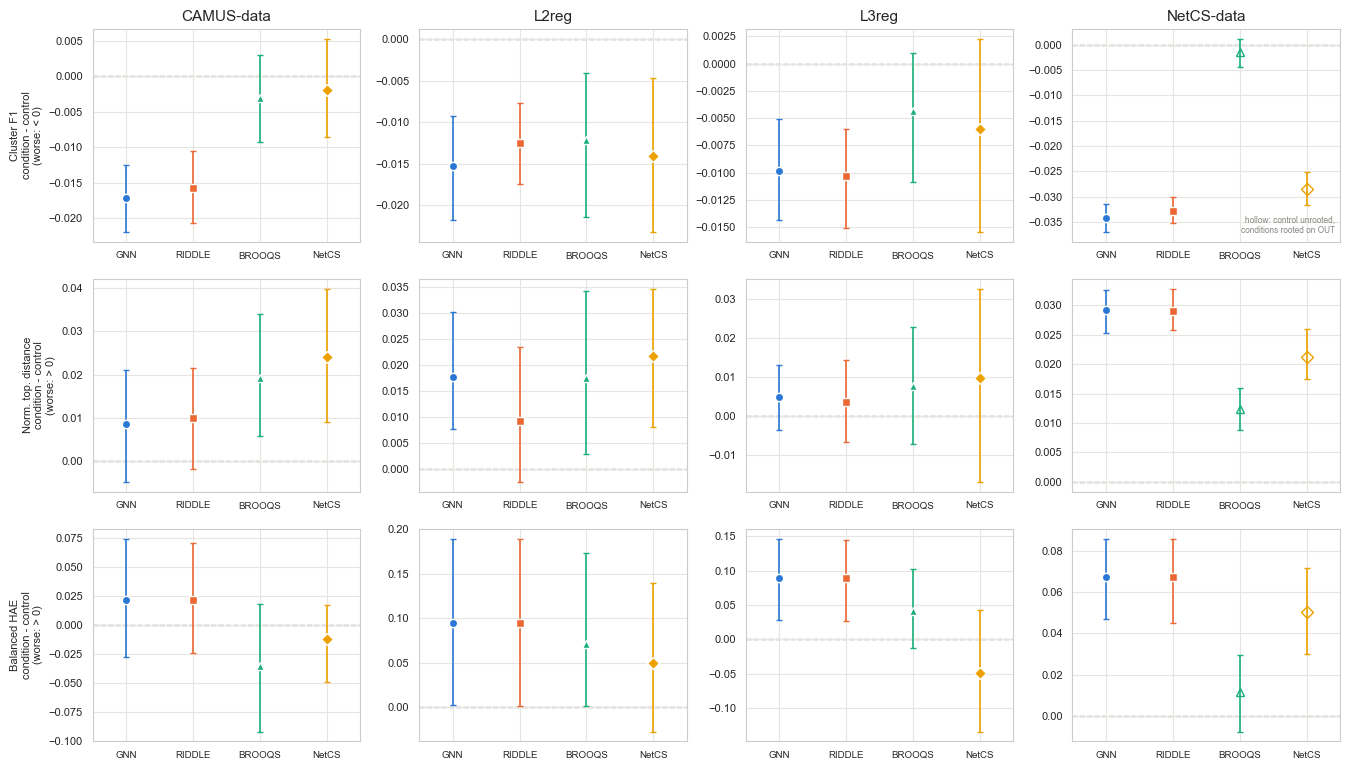

protocol     n  mean d  \
dataset    condition metric            method                                  
CAMUS-data p0.90_c24 cluster_f1        GNN              paired    80 -0.0172   
                                       GNN MAP [z+tc]   paired    80 -0.0158   
                                       BROOQS           paired    80 -0.0030   
                                       NetCS            paired    80 -0.0018   
                     luay_norm_exact   GNN              paired    80  0.0085   
                                       GNN MAP [z+tc]   paired    80  0.0101   
                                       BROOQS           paired    80  0.0193   
                                       NetCS            paired    64  0.0240   
                     ha_balanced_error GNN              paired    80  0.0211   
                                       GNN MAP [z+tc]   paired    80  0.0211   
                                       BROOQS           paired    77 -0.0354   
                                       NetCS            paired    76 -0.0126   
L2reg      p0.90_c24 cluster_f1        GNN              paired    19 -0.0153   
                                       GNN MAP [z+tc]   paired    19 -0.0125   
                                       BROOQS           paired    19 -0.0121   
                                       NetCS            paired    19 -0.0141   
                     luay_norm_exact   GNN              paired    19  0.0177   
                                       GNN MAP [z+tc]   paired    19  0.0093   
                                       BROOQS           paired    19  0.0175   
                                       NetCS            paired    18  0.0217   
                     ha_balanced_error GNN              paired    19  0.0946   
                                       GNN MAP [z+tc]   paired    19  0.0946   
                                       BROOQS           paired    19  0.0708   
                                       NetCS            paired    19  0.0492   
L3reg      p0.90_c24 cluster_f1        GNN              paired    20 -0.0099   
                                       GNN MAP [z+tc]   paired    20 -0.0103   
                                       BROOQS           paired    20 -0.0043   
                                       NetCS            paired    19 -0.0060   
                     luay_norm_exact   GNN              paired    20  0.0050   
                                       GNN MAP [z+tc]   paired    20  0.0037   
                                       BROOQS           paired    20  0.0077   
                                       NetCS            paired    10  0.0097   
                     ha_balanced_error GNN              paired    20  0.0890   
                                       GNN MAP [z+tc]   paired    20  0.0890   
                                       BROOQS           paired    20  0.0409   
                                       NetCS            paired    19 -0.0492   
NetCS-data p0.90_c24 cluster_f1        GNN              paired  1183 -0.0341   
                                       GNN MAP [z+tc]   paired  1183 -0.0328   
                                       BROOQS            cross  1181 -0.0015   
                                       NetCS             cross  1118 -0.0285   
                     luay_norm_exact   GNN              paired  1183  0.0292   
                                       GNN MAP [z+tc]   paired  1183  0.0291   
                                       BROOQS            cross  1181  0.0123   
                                       NetCS             cross   821  0.0213   
                     ha_balanced_error GNN              paired  1183  0.0672   
                                       GNN MAP [z+tc]   paired  1183  0.0672   
                                       BROOQS            cross  1159  0.0116   
                                       NetCS             cross  1047  0.0503   

                                                     

In [5]:
trows = []
if FAM_LIST:
    fig, axes = plt.subplots(len(METRICS), len(FAM_LIST), figsize=(3.4 * len(FAM_LIST), 2.6 * len(METRICS)),
                             squeeze=False)
    for j, fam in enumerate(FAM_LIST):
        conds = CONDS[fam]
        off = np.linspace(-0.25, 0.25, len(conds)) if len(conds) > 1 else [0.0]
        for i, (col, name, better) in enumerate(METRICS):
            ax = axes[i, j]
            for k, cond in enumerate(conds):
                for x, m in enumerate(METHODS):
                    d = paired(fam, col, cond, m)
                    mu, lo, hi = boot_mean(d.values)
                    hollow = (fam, m) in CROSS_PROTOCOL
                    if not np.isnan(mu):
                        ax.errorbar(x + off[k], mu, yerr=[[mu - lo], [hi - mu]], fmt=MARKER[m], color=COLOR[m],
                                    mec=COLOR[m] if hollow else "white", mfc="none" if hollow else COLOR[m], ms=6,
                                    capsize=2, lw=1.2, alpha=shade([CONTROL, *conds])[cond])
                    sign = 1 if better == "higher" else -1
                    trows.append({"dataset": TITLES[fam], "condition": cond, "metric": col, "method": m,
                                  "protocol": "cross" if hollow else "paired",
                                  "n": len(d), "mean d": d.mean() if len(d) else np.nan,
                                  "median d": d.median() if len(d) else np.nan,
                                  "worse": int((sign * d < 0).sum()), "better": int((sign * d > 0).sum()),
                                  "tied": int((d == 0).sum()), "wilcoxon p": wilcoxon_p(d)})
            ax.axhline(0, color=ZERO_C, lw=1, ls="--", zorder=0)
            if not ax.lines[:-1] and not ax.collections:
                ax.text(0.5, 0.5, "no paired cells yet", transform=ax.transAxes, ha="center", color=REF_C, fontsize=8)
            if i == 0 and any((fam, m) in CROSS_PROTOCOL for m in METHODS):
                ax.text(0.98, 0.03, "hollow: control unrooted,\nconditions rooted on OUT", transform=ax.transAxes,
                        ha="right", va="bottom", color=REF_C, fontsize=6)
            ax.set_xlim(-0.5, len(METHODS) - 0.5)
            ax.set_xticks(range(len(METHODS)))
            ax.set_xticklabels([LABELS[m] for m in METHODS], fontsize=7)
            ax.tick_params(axis="y", labelsize=8)
            if i == 0:
                ax.set_title(TITLES[fam], fontsize=11)
            if j == 0:
                ax.set_ylabel(f"{name}\ncondition - control\n(worse: {'< 0' if better == 'higher' else '> 0'})", fontsize=8)
    fig.tight_layout()
    save(fig, "AllDatasets", "delta")
    plt.show()
DELTA = pd.DataFrame(trows)
if len(DELTA):
    DELTA = DELTA[DELTA.n > 0]
    display(DELTA.set_index(["dataset", "condition", "metric", "method"]).round(4))

## 3. Does RIDDLE's edge survive missing taxa?

Per cell, RIDDLE − comparator (the vanilla GNN, BROOQS, NetCS), in the control and under each condition; each
comparison is within one protocol. A point above 0 on cluster F1 (below 0 on the
two errors) is RIDDLE ahead.

wrote ../plots/AllDatasets-taxmiss-map-edge-ours_l2mix_pair_selF1.png


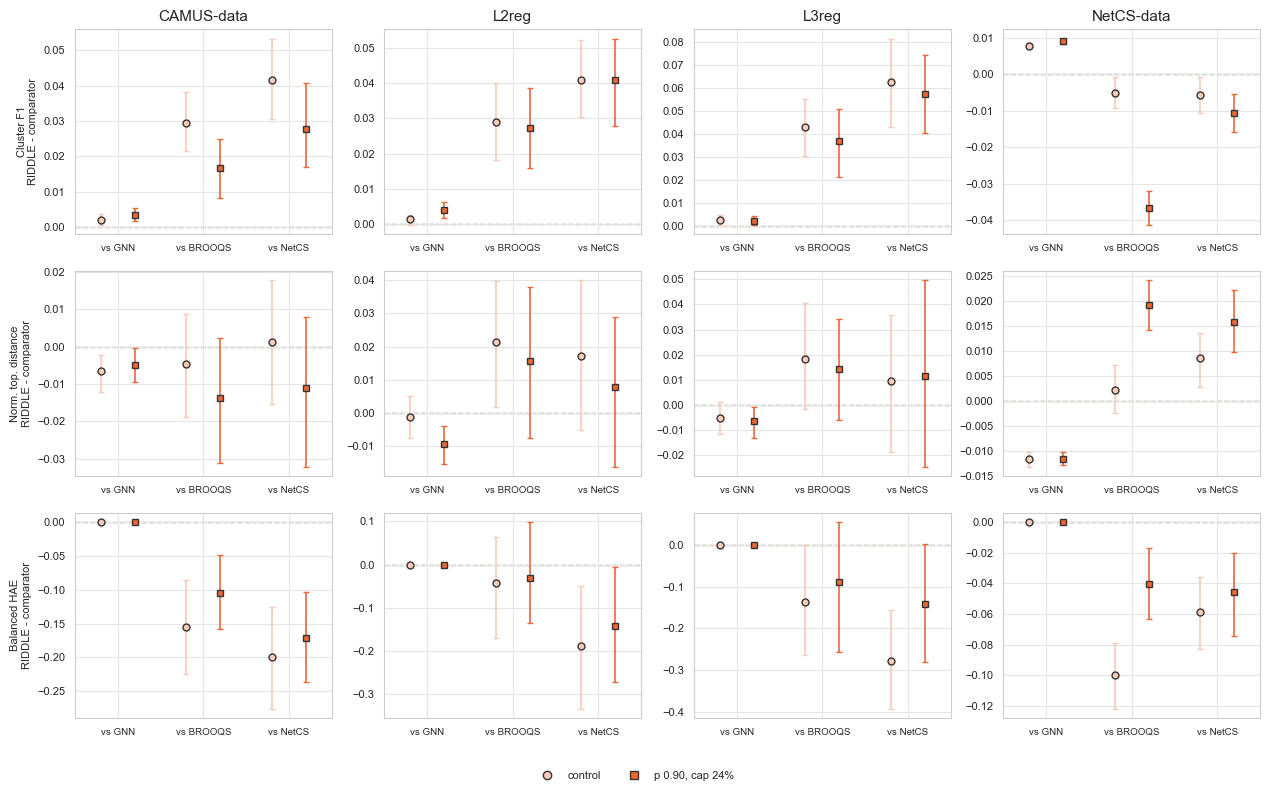

n  mean d  RIDDLE better  \
dataset    condition metric            vs                                    
CAMUS-data control   cluster_f1        GNN       80  0.0021             22   
                                       BROOQS    80  0.0293             59   
                                       NetCS     80  0.0415             64   
           p0.90_c24 cluster_f1        GNN       80  0.0035             30   
                                       BROOQS    80  0.0166             50   
...                                             ...     ...            ...   
NetCS-data control   ha_balanced_error BROOQS  1166 -0.1000            634   
                                       NetCS   1122 -0.0586            534   
           p0.90_c24 ha_balanced_error GNN     1200  0.0000              0   
                                       BROOQS  1190 -0.0401            586   
                                       NetCS   1087 -0.0453            516   

                                               RIDDLE worse  tied  wilcoxon p  
dataset    condition metric            vs                                      
CAMUS-data control   cluster_f1        GNN                6    52      0.0025  
                                       BROOQS            15     6      0.0000  
                                       NetCS             12     4      0.0000  
           p0.90_c24 cluster_f1        GNN                9    41      0.0003  
                                       BROOQS            25     5      0.0009  
...                                                     ...   ...         ...  
NetCS-data control   ha_balanced_error BROOQS           416   116      0.0000  
                                       NetCS            428   160      0.0000  
           p0.90_c24 ha_balanced_error GNN                0  1200         NaN  
                                       BROOQS           452   152      0.0003  
                                       NetCS            453   118      0.0029  

[72 rows x 6 columns]

In [6]:
erows = []
COMP = ["GNN", "BROOQS", "NetCS"]
if FAM_LIST:
    fig, axes = plt.subplots(len(METRICS), len(FAM_LIST), figsize=(3.2 * len(FAM_LIST), 2.6 * len(METRICS)),
                             squeeze=False)
    for j, fam in enumerate(FAM_LIST):
        conds = [CONTROL, *CONDS[fam]]
        off = np.linspace(-0.2, 0.2, len(conds))
        d = ACC[ACC.family == fam]
        for i, (col, name, better) in enumerate(METRICS):
            ax = axes[i, j]
            for k, cond in enumerate(conds):
                w = d[d.cond == cond].set_index(["cell", "method"])[col].unstack("method")
                for x, other in enumerate(COMP):
                    if MAP_M not in w or other not in w:
                        continue
                    diff = (w[MAP_M] - w[other]).dropna()
                    mu, lo, hi = boot_mean(diff.values)
                    if np.isnan(mu):
                        continue
                    c = tint(COLOR[MAP_M], shade(conds)[cond])
                    ax.errorbar(x + off[k], mu, yerr=[[mu - lo], [hi - mu]], fmt="s" if cond != CONTROL else "o",
                                color=c, mec="#333", ms=5, capsize=2, lw=1.2)
                    sign = 1 if better == "higher" else -1
                    erows.append({"dataset": TITLES[fam], "condition": cond, "metric": col, "vs": other,
                                  "n": len(diff), "mean d": diff.mean(), f"{MAP_NAME} better": int((sign * diff > 0).sum()),
                                  f"{MAP_NAME} worse": int((sign * diff < 0).sum()), "tied": int((diff == 0).sum()),
                                  "wilcoxon p": wilcoxon_p(diff)})
            ax.axhline(0, color=ZERO_C, lw=1, ls="--", zorder=0)
            ax.set_xlim(-0.5, len(COMP) - 0.5)
            ax.set_xticks(range(len(COMP)))
            ax.set_xticklabels([f"vs {c}" for c in COMP], fontsize=7)
            ax.tick_params(axis="y", labelsize=8)
            if i == 0:
                ax.set_title(TITLES[fam], fontsize=11)
            if j == 0:
                ax.set_ylabel(f"{name}\n{MAP_NAME} - comparator", fontsize=8)
    handles = [Line2D([], [], marker="o" if c == CONTROL else "s", ls="", mec="#333",
                      color=tint(COLOR[MAP_M], shade([CONTROL, *ALL_CONDS])[c]), label=cond_label(c))
               for c in [CONTROL, *ALL_CONDS]]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8,
               bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    save(fig, "AllDatasets", "map-edge")
    plt.show()
EDGE = pd.DataFrame(erows)
if len(EDGE):
    display(EDGE.set_index(["dataset", "condition", "metric", "vs"]).round(4))

## 4. CAMUS by size

Mean per n (50..200). Dashed is the control, solid the condition (one column per condition). Fewer taxa per tree
is a larger *share* at small n: M is the cap's share of n, but the mean share deleted falls with n (§0).

wrote ../plots/CAMUS-taxmiss-by-n-ours_l2mix_pair_selF1.png


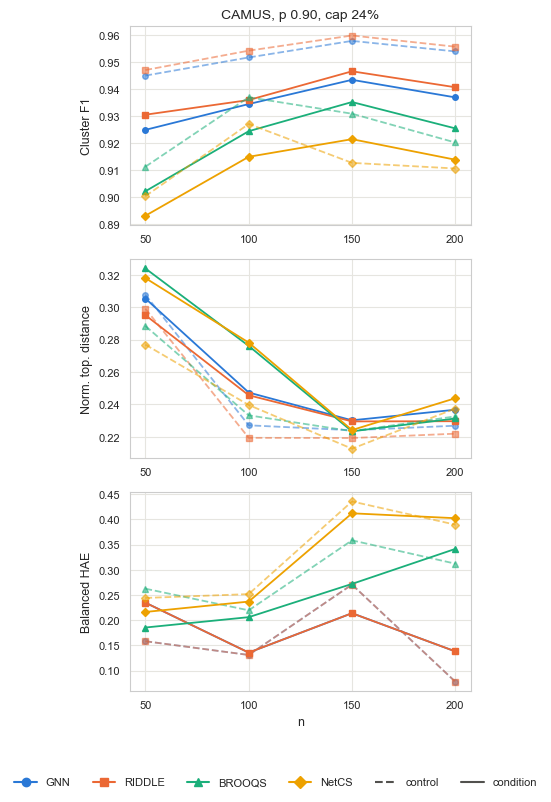

In [7]:
if "camus" in FAM_LIST:
    d = ACC[ACC.family == "camus"].copy()
    d["n"] = d.n.astype(int)
    conds = CONDS["camus"]
    fig, axes = plt.subplots(len(METRICS), len(conds), figsize=(4.2 * len(conds), 2.6 * len(METRICS)), squeeze=False)
    for j, cond in enumerate(conds):
        for i, (col, name, better) in enumerate(METRICS):
            ax = axes[i, j]
            for m in METHODS:
                for c, ls in ((CONTROL, "--"), (cond, "-")):
                    s = d[(d.method == m) & (d.cond == c)].groupby("n")[col].mean()
                    if len(s):
                        ax.plot(s.index, s.values, ls=ls, marker=MARKER[m], color=COLOR[m], ms=4, lw=1.3,
                                alpha=0.55 if c == CONTROL else 1)
            ax.set_xticks(sorted(d.n.unique()))
            ax.tick_params(labelsize=8)
            if i == 0:
                ax.set_title(f"CAMUS, {cond_label(cond)}", fontsize=10)
            if j == 0:
                ax.set_ylabel(name, fontsize=9)
            if i == len(METRICS) - 1:
                ax.set_xlabel("n", fontsize=9)
    handles = [Line2D([], [], color=COLOR[m], marker=MARKER[m], label=LABELS[m].replace("\n", " ")) for m in METHODS]
    handles += [Line2D([], [], color=INK, ls="--", label="control"), Line2D([], [], color=INK, ls="-", label="condition")]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    save(fig, "CAMUS", "by-n")
    plt.show()

## 5. The tree of blobs under missing taxa

TOB error is (missed + extra edges) / true edges of TREE-QMC's raw TOB, by splits against the true TOB — the
condition's (from its JSON) beside the control's (the published full-data TOB, scored the same way; `make_csv` holds the
split comparison to the JSON's own numbers). Right: each resolver's cluster F1 against its cell's TOB error under the
condition; the dashed line is the GNN's median.

wrote ../plots/AllDatasets-taxmiss-tob-ours_l2mix_pair_selF1.png


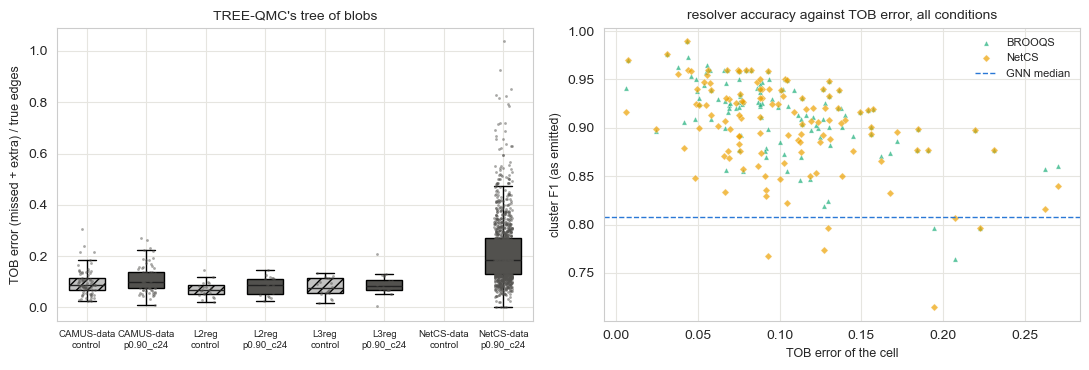

tob_err         ctrl_tob_err        
                    mean  median         mean  median
family cond                                          
camus  p0.90_c24  0.1104  0.1006       0.0966  0.0867
l2reg  p0.90_c24  0.0834  0.0885       0.0707  0.0684
l3reg  p0.90_c24  0.0911  0.0829       0.0789  0.0746
netcs  p0.90_c24  0.2163  0.1859          NaN     NaN

In [8]:
if len(PN) and "tob_fn_raw" in PN:
    cellw = PN.drop_duplicates(["family", "cond", "cell"]).copy()
    cellw = cellw[cellw.arm != "cam_iq500"]
    cellw["tob_err"] = (cellw.tob_fn_raw + cellw.tob_fp_raw) / cellw.tob_true_edges
    cellw["ctrl_tob_err"] = (cellw.ctrl_tob_fn_raw + cellw.ctrl_tob_fp_raw) / cellw.tob_true_edges
    fams = [f for f in FAM_LIST if f in set(cellw.family)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    ax = axes[0]
    labels, k = [], 0
    for fam in fams:
        for cond in CONDS[fam]:
            w = cellw[(cellw.family == fam) & (cellw.cond == cond)]
            for c, col, f in ((CONTROL, "ctrl_tob_err", 0.35), (cond, "tob_err", 1.0)):
                v = w[col].dropna().values
                if len(v):
                    bp = ax.boxplot([v], positions=[k], widths=0.6, patch_artist=True, showfliers=False,
                                    medianprops=dict(color="#222"))
                    bp["boxes"][0].set_facecolor(tint("#52514e", f))
                    if c == CONTROL:
                        bp["boxes"][0].set_hatch("///")
                    ax.scatter(k + RNG.uniform(-0.15, 0.15, len(v)), v, s=4, color=INK, alpha=0.5, lw=0, zorder=3)
                labels.append(f"{TITLES[fam]}\n{'control' if c == CONTROL else c}")
                k += 1
    ax.set_xticks(range(k))
    ax.set_xticklabels(labels, fontsize=7)
    ax.set_ylabel("TOB error (missed + extra) / true edges", fontsize=9)
    ax.set_title("TREE-QMC's tree of blobs", fontsize=10)
    ax = axes[1]
    r = PN[PN.method.isin(["BROOQS", "NetCS"]) & (PN.arm != "cam_iq500")].copy()
    r["tob_err"] = (r.tob_fn_raw + r.tob_fp_raw) / r.tob_true_edges
    for m in ("BROOQS", "NetCS"):
        s = r[r.method == m]
        ax.scatter(s.tob_err, s.cluster_f1, marker=MARKER[m], color=COLOR[m], s=14, alpha=0.7, lw=0.3,
                   edgecolor="white", label=m)
    g = PN[PN.method.str.startswith("ours/") & (PN.arm != "cam_iq500")]
    if len(g):
        ax.axhline(g.cluster_f1.median(), color=COLOR["GNN"], ls="--", lw=1, label="GNN median")
    ax.set_xlabel("TOB error of the cell", fontsize=9)
    ax.set_ylabel("cluster F1 (as emitted)", fontsize=9)
    ax.set_title("resolver accuracy against TOB error, all conditions", fontsize=10)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    save(fig, "AllDatasets", "tob")
    plt.show()
    display(cellw.groupby(["family", "cond"])[["tob_err", "ctrl_tob_err"]].agg(["mean", "median"]).round(4))

## 6. Per-cell cost against how much was deleted

Each point is a cell: its paired change (condition − control) against the share of taxa its trees lost
(`mean_missing`, the MANIFEST's). One colour per method, a least-squares line each.

wrote ../plots/AllDatasets-taxmiss-missingness-ours_l2mix_pair_selF1.png


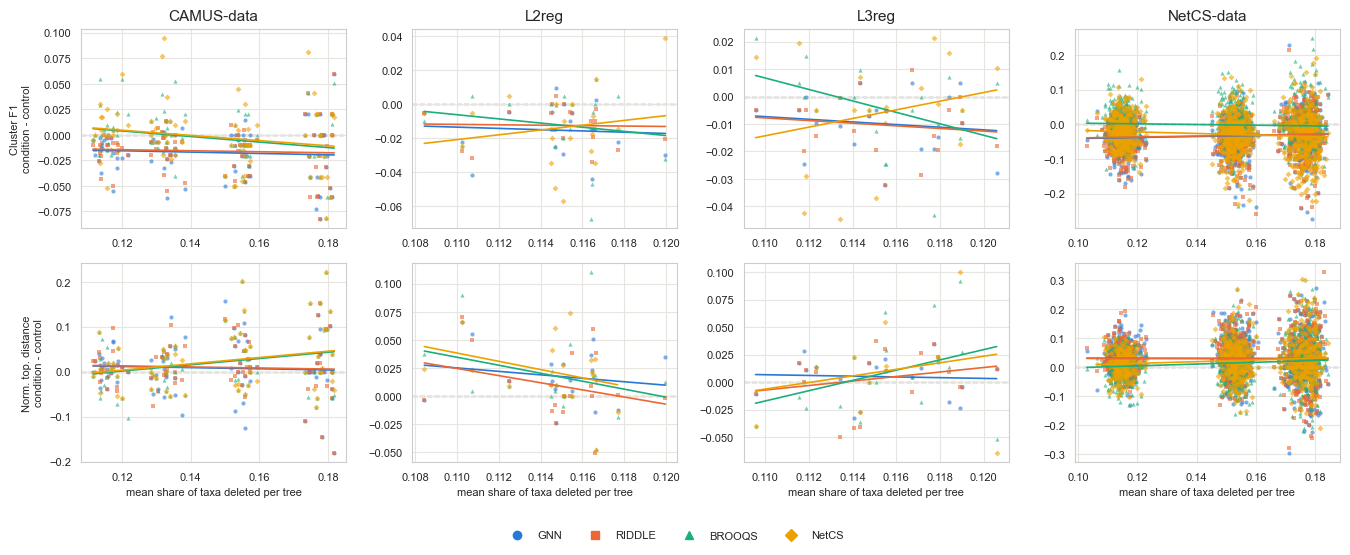

In [9]:
if FAM_LIST and len(MAN):
    mm = MAN.set_index(["family", "cond", "cell"]).mean_missing
    fig, axes = plt.subplots(2, len(FAM_LIST), figsize=(3.4 * len(FAM_LIST), 5.4), squeeze=False)
    for j, fam in enumerate(FAM_LIST):
        for i, (col, name, better) in enumerate(METRICS[:2]):
            ax = axes[i, j]
            for m in METHODS:
                xs, ys = [], []
                for cond in CONDS[fam]:
                    d = paired(fam, col, cond, m)
                    for cell, v in d.items():
                        if (fam, cond, cell) in mm.index:
                            xs.append(mm[(fam, cond, cell)])
                            ys.append(v)
                if not xs:
                    continue
                ax.scatter(xs, ys, s=9, marker=MARKER[m], color=COLOR[m], alpha=0.6, lw=0)
                if len(xs) > 2 and np.ptp(xs) > 0:
                    b1, b0 = np.polyfit(xs, ys, 1)
                    xx = np.linspace(min(xs), max(xs), 10)
                    ax.plot(xx, b0 + b1 * xx, color=COLOR[m], lw=1.2)
            ax.axhline(0, color=ZERO_C, lw=1, ls="--", zorder=0)
            ax.tick_params(labelsize=8)
            if i == 0:
                ax.set_title(TITLES[fam], fontsize=11)
            if j == 0:
                ax.set_ylabel(f"{name}\ncondition - control", fontsize=8)
            if i == 1:
                ax.set_xlabel("mean share of taxa deleted per tree", fontsize=8)
    handles = [Line2D([], [], color=COLOR[m], marker=MARKER[m], ls="", label=LABELS[m].replace("\n", " ")) for m in METHODS]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    save(fig, "AllDatasets", "missingness")
    plt.show()

## 7. Across conditions: deletion probability × cap

Mean paired change (condition − control) per method on the (p, cap) grid. Drawn once a dataset has at least two
conditions staged; until then this cell says so.

In [10]:
multi = [f for f in FAM_LIST if len(CONDS[f]) >= 2]
if not multi:
    print("one condition per dataset so far:", {f: CONDS[f] for f in FAM_LIST}, "-- figure 7 waits for more")
else:
    for col, name, better in METRICS:
        fig, axes = plt.subplots(len(METHODS), len(multi), figsize=(2.8 * len(multi), 2.3 * len(METHODS)),
                                 squeeze=False)
        for j, fam in enumerate(multi):
            ps = sorted({cond_pc(c)[0] for c in CONDS[fam]})
            caps = sorted({cond_pc(c)[1] for c in CONDS[fam]})
            for i, m in enumerate(METHODS):
                grid = np.full((len(caps), len(ps)), np.nan)
                for cond in CONDS[fam]:
                    p, cap = cond_pc(cond)
                    d = paired(fam, col, cond, m)
                    if len(d):
                        grid[caps.index(cap), ps.index(p)] = d.mean()
                ax = axes[i, j]
                lim = np.nanmax(np.abs(grid)) if np.isfinite(grid).any() else 1
                cmap = "RdBu" if better == "higher" else "RdBu_r"
                im = ax.imshow(grid, cmap=cmap, vmin=-lim, vmax=lim, origin="lower", aspect="auto")
                for (a, b), v in np.ndenumerate(grid):
                    if np.isfinite(v):
                        ax.text(b, a, f"{v:+.3f}", ha="center", va="center", fontsize=7)
                ax.set_xticks(range(len(ps)))
                ax.set_xticklabels([f"{p:.2f}" for p in ps], fontsize=7)
                ax.set_yticks(range(len(caps)))
                ax.set_yticklabels([f"{c}%" for c in caps], fontsize=7)
                if i == 0:
                    ax.set_title(TITLES[fam], fontsize=10)
                if j == 0:
                    ax.set_ylabel(f"{LABELS[m].replace(chr(10), ' ')}\ncap", fontsize=8)
                if i == len(METHODS) - 1:
                    ax.set_xlabel("p", fontsize=8)
        fig.suptitle(f"{name}: mean condition - control (blue is better)", fontsize=10)
        fig.tight_layout()
        save(fig, "AllDatasets", f"grid-{col.replace('_', '-')}")
        plt.show()

one condition per dataset so far: {'camus': ['p0.90_c24'], 'l2reg': ['p0.90_c24'], 'l3reg': ['p0.90_c24'], 'netcs': ['p0.90_c24']} -- figure 7 waits for more


## 8. Runtime

GNN: wall seconds per network, preparation + model (`run_gnn_cpu.py`'s clocks, one thread), against the control's
(`<ds>_runtime.csv`). Resolvers: CPU seconds on the TOB, against the control's; the TOB itself (TREE-QMC on the Linux
box) is not charged on either side. RIDDLE's add-on (the MAP over the GNN's blocks) is not timed here (`time_addon.py` has no taxmiss path). On NetCS the
control's resolver times are the unrooted runs.

wrote ../plots/AllDatasets-taxmiss-runtime-ours_l2mix_pair_selF1.png


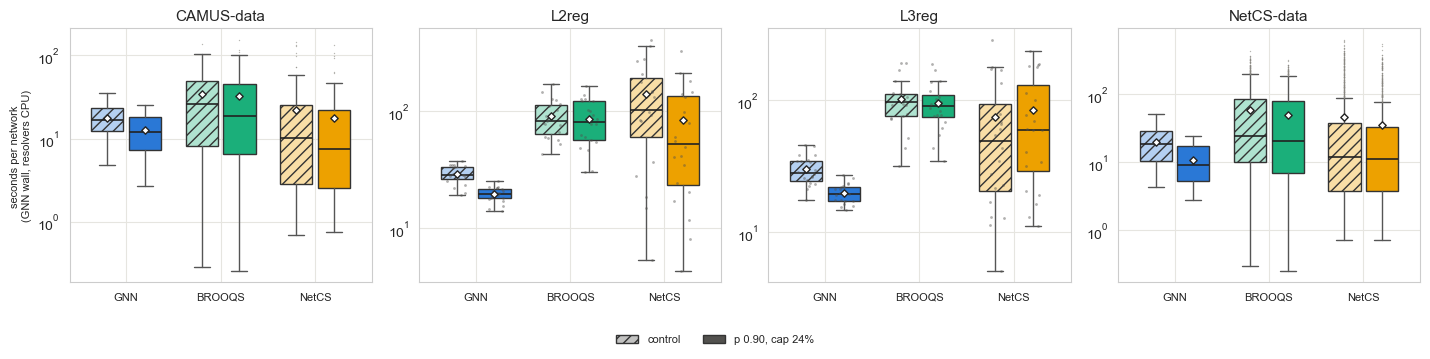

n  median s  total h
dataset    condition method                         
CAMUS-data control   GNN       80    16.921    0.392
           p0.90_c24 GNN       80    11.964    0.282
           control   BROOQS    80    25.765    0.754
           p0.90_c24 BROOQS    80    18.906    0.719
           control   NetCS     80    10.119    0.485
           p0.90_c24 NetCS     80     7.528    0.393
L2reg      control   GNN       19    28.181    0.151
           p0.90_c24 GNN       20    19.456    0.108
           control   BROOQS    19    82.690    0.478
           p0.90_c24 BROOQS    20    81.116    0.477
           control   NetCS     19   101.996    0.741
           p0.90_c24 NetCS     20    52.455    0.466
L3reg      control   GNN       20    28.028    0.167
           p0.90_c24 GNN       20    19.587    0.111
           control   BROOQS    20    96.479    0.567
           p0.90_c24 BROOQS    20    90.536    0.532
           control   NetCS     20    48.785    0.412
           p0.90_c24 NetCS     20    59.861    0.471
NetCS-data control   GNN     1183    18.304    6.502
           p0.90_c24 GNN     1200     9.165    3.606
           control   BROOQS  1183    24.664   19.055
           p0.90_c24 BROOQS  1200    20.745   16.265
           control   NetCS   1183    11.812   15.113
           p0.90_c24 NetCS   1200    11.245   11.594

In [11]:
if len(PN) and len(RTC):
    fig, axes = plt.subplots(1, len(FAM_LIST), figsize=(3.6 * len(FAM_LIST), 3.4), squeeze=False)
    rt = PN[PN.arm != "cam_iq500"].copy()
    rt["sec"] = np.where(rt.method.str.startswith("ours/"), rt.prep_wall + rt.model_wall, rt.resolver_cpu)
    rt["m"] = np.where(rt.method.str.startswith("ours/"), "GNN", rt.method.str.replace("*", "", regex=False))
    rows = []
    for j, fam in enumerate(FAM_LIST):
        ax = axes[0, j]
        conds = [CONTROL, *CONDS[fam]]
        data = {}
        c = RTC[RTC.family == fam]
        for m in ("GNN", "BROOQS", "NetCS"):
            s = c[c.method == m]
            data[(m, CONTROL)] = (s.gnn_wall_s if m == "GNN" else s.method_cpu_s).values
            for cond in CONDS[fam]:
                data[(m, cond)] = rt[(rt.family == fam) & (rt.cond == cond) & (rt.m == m)].sec.values
            for cond in conds:
                v = np.asarray(data[(m, cond)], float)
                rows.append({"dataset": TITLES[fam], "condition": cond, "method": m, "n": int(np.isfinite(v).sum()),
                             "median s": np.nanmedian(v) if np.isfinite(v).any() else np.nan,
                             "total h": np.nansum(v) / 3600})
        grouped_boxes(ax, data, ["GNN", "BROOQS", "NetCS"], conds)
        ax.set_yscale("log")
        ax.set_title(TITLES[fam], fontsize=11)
        if j == 0:
            ax.set_ylabel("seconds per network\n(GNN wall, resolvers CPU)", fontsize=8)
    cond_legend(fig, [CONTROL, *ALL_CONDS], loc="lower center", ncol=1 + len(ALL_CONDS), bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    save(fig, "AllDatasets", "runtime")
    plt.show()
    display(pd.DataFrame(rows).set_index(["dataset", "condition", "method"]).round(3))

## 9. Summary

In [12]:
if len(ACC):
    s = (ACC[ACC.family.isin(FAM_LIST)]
         .groupby(["family", "cond", "method"])[[c for c, _, _ in METRICS]].median()
         .rename(index=TITLES, level="family"))
    display(s.round(4))
print("MISSING:" if MISSING else "MISSING: nothing")
for m in MISSING:
    print("  ", m)

cluster_f1  luay_norm_exact  \
family     cond      method                                        
CAMUS-data control   BROOQS              0.9296           0.2404   
                     GNN                 0.9538           0.2288   
                     GNN MAP [z+tc]      0.9571           0.2236   
                     NetCS               0.9266           0.2516   
           p0.90_c24 BROOQS              0.9252           0.2488   
                     GNN                 0.9406           0.2494   
                     GNN MAP [z+tc]      0.9437           0.2411   
                     NetCS               0.9192           0.2697   
L2reg      control   BROOQS              0.9167           0.2260   
                     GNN                 0.9489           0.2629   
                     GNN MAP [z+tc]      0.9489           0.2582   
                     NetCS               0.9010           0.2354   
           p0.90_c24 BROOQS              0.9125           0.2433   
                     GNN                 0.9390           0.2729   
                     GNN MAP [z+tc]      0.9413           0.2729   
                     NetCS               0.8894           0.2598   
L3reg      control   BROOQS              0.9004           0.2719   
                     GNN                 0.9276           0.2881   
                     GNN MAP [z+tc]      0.9327           0.2791   
                     NetCS               0.8878           0.2782   
           p0.90_c24 BROOQS              0.8899           0.2767   
                     GNN                 0.9151           0.2976   
                     GNN MAP [z+tc]      0.9178           0.2828   
                     NetCS               0.8634           0.2911   
NetCS-data control   BROOQS              0.8462           0.3519   
                     GNN                 0.8400           0.3611   
                     GNN MAP [z+tc]      0.8491           0.3474   
                     NetCS               0.8513           0.3429   
           p0.90_c24 BROOQS              0.8443           0.3679   
                     GNN                 0.8000           0.3922   
                     GNN MAP [z+tc]      0.8084           0.3824   
                     NetCS               0.8227           0.3725   

                                     ha_balanced_error  
family     cond      method                             
CAMUS-data control   BROOQS                     0.2500  
                     GNN                        0.0000  
                     GNN MAP [z+tc]             0.0000  
                     NetCS                      0.4410  
           p0.90_c24 BROOQS                     0.2143  
                     GNN                        0.0000  
                     GNN MAP [z+tc]             0.0000  
                     NetCS                      0.4361  
L2reg      control   BROOQS                     0.3393  
                     GNN                        0.1997  
                     GNN MAP [z+tc]             0.1997  
                     NetCS                      0.4350  
           p0.90_c24 BROOQS                     0.4079  
                     GNN                        0.3510  
                     GNN MAP [z+tc]             0.3510  
                     NetCS                      0.4577  
L3reg      control   BROOQS                     0.4183  
                     GNN                        0.1962  
                     GNN MAP [z+tc]             0.1962  
                     NetCS                      0.5825  
           p0.90_c24 BROOQS                     0.4368  
                     GNN                        0.3649  
                     GNN MAP [z+tc]             0.3649  
                     NetCS                      0.4818  
NetCS-data control   BROOQS                     0.4826  
                     GNN                        0.4167  
                     GNN MAP [z+tc]             0.4167  
                     NetCS                      0.4700  
           p0.

MISSING: nothing
